<a href="https://colab.research.google.com/github/sergeydorof/neural_networks_labs/blob/main/lab2/nn_lab2_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

data = pd.read_csv('drive/MyDrive/Volgograd_weather.csv', encoding='windows-1251', sep=';')
data

,LocalTime,T,P0,P,U,DD
0,15.10.2020 23:00,11.0,752.2,764.3,88.0,Ветер
1,15.10.2020 22:00,10.0,752.1,764.3,88.0,Ветер
2,15.10.2020 21:00,13.0,752.3,764.3,82.0,Ветер
3,15.10.2020 20:30,13.0,752.3,764.3,82.0,Ветер
4,15.10.2020 20:00,13.0,752.3,764.3,88.0,Ветер
...,...,...,...,...,...,...
117265,15.10.2012 04:00,7.0,756.5,768.9,71.0,Ветер
117266,15.10.2012 03:00,6.0,757.2,769.6,76.0,Ветер
117267,15.10.2012 02:00,5.0,757.1,769.6,81.0,Ветер
117268,15.10.2012 01:00,6.0,756.5,768.9,81.0,Ветер


In [ ]:
data['LocalTime'] = pd.to_datetime(data['LocalTime'], format='%d.%m.%Y %H:%M')
data = data.set_index('LocalTime')
data = data.sort_index()
data

,T,P0,P,U,DD
LocalTime,,,,,
2012-10-15 00:00:00,5.0,756.4,768.9,76.0,Ветер
2012-10-15 01:00:00,6.0,756.5,768.9,81.0,Ветер
2012-10-15 02:00:00,5.0,757.1,769.6,81.0,Ветер
2012-10-15 03:00:00,6.0,757.2,769.6,76.0,Ветер
2012-10-15 04:00:00,7.0,756.5,768.9,71.0,Ветер
...,...,...,...,...,...
2020-10-15 20:00:00,13.0,752.3,764.3,88.0,Ветер
2020-10-15 20:30:00,13.0,752.3,764.3,82.0,Ветер
2020-10-15 21:00:00,13.0,752.3,764.3,82.0,Ветер


In [ ]:
is_unique = data.index.is_unique
print(f"Индекс LocalTime является уникальным: {is_unique}")
if not is_unique:
    print(f"Количество дублирующихся временных меток в индексе: {data.index.duplicated().sum()}")

Индекс LocalTime является уникальным: True


In [ ]:
duplicate_rows_count = data.duplicated().sum()
print(f"Количество полных дубликатов строк в датасете (без учета индекса): {duplicate_rows_count}")

duplicate_with_index = data.reset_index().duplicated().sum()
print(f"Количество полных дубликатов строк (включая индекс LocalTime): {duplicate_with_index}")

Количество полных дубликатов строк в датасете (без учета индекса): 95580
Количество полных дубликатов строк (включая индекс LocalTime): 0


In [ ]:
missing_values = data.isna().sum()
print("Количество пропусков по столбцам:")
print(missing_values)

print(f"\nПропусков в индексе LocalTime: {data.index.isna().sum()}")

Количество пропусков по столбцам:
T     6
P0    7
P     3
U     6
DD    7
dtype: int64

Пропусков в индексе LocalTime: 0


In [ ]:
data_cleaned = data.dropna()

print(f"Исходное количество строк: {len(data)}")
print(f"Количество строк после удаления пропусков: {len(data_cleaned)}")
print(f"Удалено строк: {len(data) - len(data_cleaned)}")

data = data_cleaned

Исходное количество строк: 117258
Количество строк после удаления пропусков: 117258
Удалено строк: 0


Теперь датасет без пропусков, надо проанализировать каждый признак по отдельности

In [ ]:
data.describe(include='all')

,T,P0,P,U,DD
count,117258.000000,117258.000000,117258.000000,117258.000000,117258
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Ветер
freq,NaN,NaN,NaN,NaN,114036
mean,9.342945,750.744452,762.941175,67.141483,NaN
std,12.250687,6.006067,6.308625,24.767213,NaN
min,-29.000000,726.800000,738.900000,7.000000,NaN
25%,0.000000,746.700000,758.200000,46.000000,NaN
50%,9.000000,750.400000,762.800000,72.000000,NaN
75%,19.000000,754.400000,766.600000,88.000000,NaN


По статистическим данным числовые признаки и таргет выглядят адекватно

In [ ]:
# Расчет целевой переменной: средняя температура на следующие сутки (24 часа)
# Мы считаем скользящее среднее по окну 24 часа вперед.
# Для этого считаем скользящее среднее в обратном порядке (инвертируя индекс) и сдвигаем его.
temp_series = data['T']

# Среднее за следующие 24 часа:
# Инвертируем временной ряд, считаем скользящее среднее за последние 24 часа (которые станут будущими для исходного ряда), и возвращаем обратно
data['target_temp_next_day'] = temp_series.iloc[::-1].rolling('24h', closed='left').mean().iloc[::-1]

# Среднее за следующую неделю (7 суток):
data['target_temp_next_week'] = temp_series.iloc[::-1].rolling('7d', closed='left').mean().iloc[::-1]

# Выведем первые строки и проверим результат
display(data[['T', 'target_temp_next_day', 'target_temp_next_week']].head(10))

,T,target_temp_next_day,target_temp_next_week
LocalTime,,,
2012-10-15 00:00:00,5.0,10.791667,12.095238
2012-10-15 01:00:00,6.0,11.083333,12.101190
2012-10-15 02:00:00,5.0,11.416667,12.107143
2012-10-15 03:00:00,6.0,11.666667,12.101190
2012-10-15 04:00:00,7.0,11.875000,12.089286
2012-10-15 05:00:00,7.0,12.041667,12.071429
2012-10-15 06:00:00,7.0,12.208333,12.047619
2012-10-15 07:00:00,7.0,12.375000,12.011905
2012-10-15 08:00:00,7.0,12.583333,11.988095


In [ ]:
# Проверим последние строки датасета.
# В самом конце таблицы значения целевых переменных должны стать NaN, так как будущих данных для расчета целых суток или недели уже нет.
display(data[['T', 'target_temp_next_day', 'target_temp_next_week']].tail(10))

,T,target_temp_next_day,target_temp_next_week
LocalTime,,,
2020-10-15 17:30:00,17.0,13.111111,13.111111
2020-10-15 18:00:00,16.0,12.750000,12.750000
2020-10-15 18:30:00,15.0,12.428571,12.428571
2020-10-15 19:00:00,14.0,12.166667,12.166667
2020-10-15 19:30:00,13.0,12.000000,12.000000
2020-10-15 20:00:00,13.0,11.750000,11.750000
2020-10-15 20:30:00,13.0,11.333333,11.333333
2020-10-15 21:00:00,13.0,10.500000,10.500000
2020-10-15 22:00:00,10.0,11.000000,11.000000


In [ ]:
data_final = data.dropna()

print(f"Количество строк до удаления новых пропусков: {len(data)}")
print(f"Количество строк после финальной очистки: {len(data_final)}")
print(f"Удалено строк в конце датасета: {len(data) - len(data_final)}")

data = data_final
data

Количество строк до удаления новых пропусков: 117258
Количество строк после финальной очистки: 117255
Удалено строк в конце датасета: 3


,T,P0,P,U,DD,target_temp_next_day,target_temp_next_week
LocalTime,,,,,,,
2012-10-15 00:00:00,5.0,756.4,768.9,76.0,Ветер,10.791667,12.095238
2012-10-15 01:00:00,6.0,756.5,768.9,81.0,Ветер,11.083333,12.101190
2012-10-15 02:00:00,5.0,757.1,769.6,81.0,Ветер,11.416667,12.107143
2012-10-15 03:00:00,6.0,757.2,769.6,76.0,Ветер,11.666667,12.101190
2012-10-15 04:00:00,7.0,756.5,768.9,71.0,Ветер,11.875000,12.089286
...,...,...,...,...,...,...,...
2020-10-15 19:30:00,13.0,752.3,764.3,82.0,Ветер,12.000000,12.000000
2020-10-15 20:00:00,13.0,752.3,764.3,88.0,Ветер,11.750000,11.750000
2020-10-15 20:30:00,13.0,752.3,764.3,82.0,Ветер,11.333333,11.333333


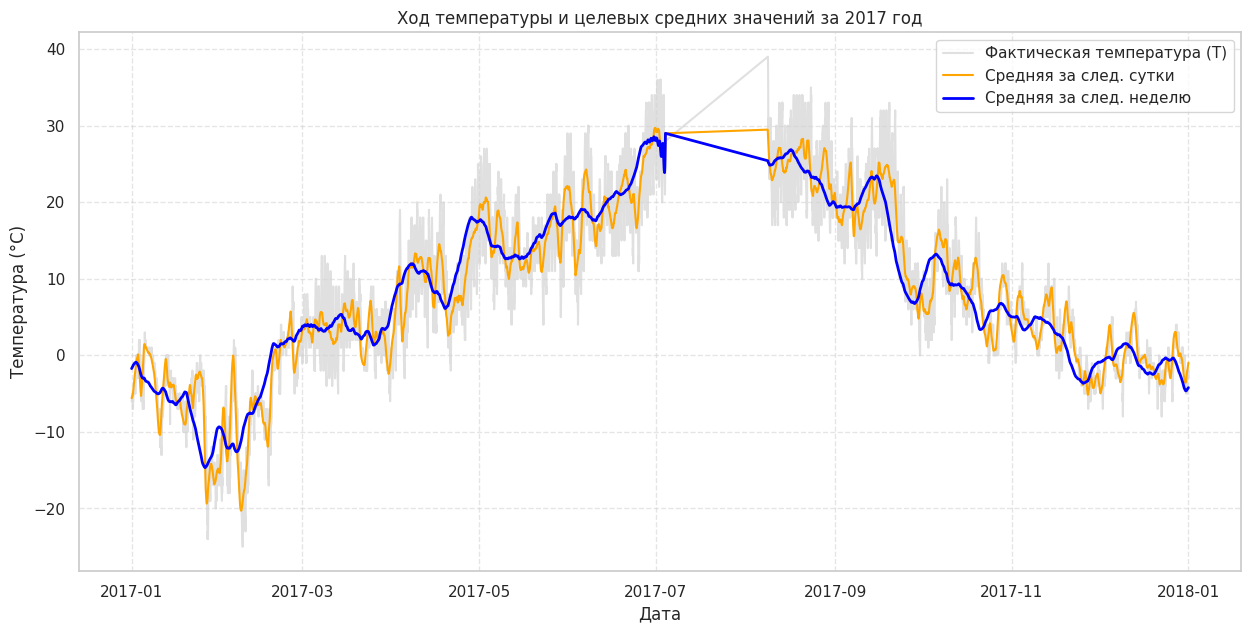

In [ ]:
import matplotlib.pyplot as plt

data_2017 = data.loc['2017']

plt.figure(figsize=(15, 7))
plt.plot(data_2017.index, data_2017['T'], label='Фактическая температура (T)', color='lightgray', alpha=0.7)
plt.plot(data_2017.index, data_2017['target_temp_next_day'], label='Средняя за след. сутки', color='orange', linewidth=1.5)
plt.plot(data_2017.index, data_2017['target_temp_next_week'], label='Средняя за след. неделю', color='blue', linewidth=2.0)

plt.title('Ход температуры и целевых средних значений за 2017 год')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

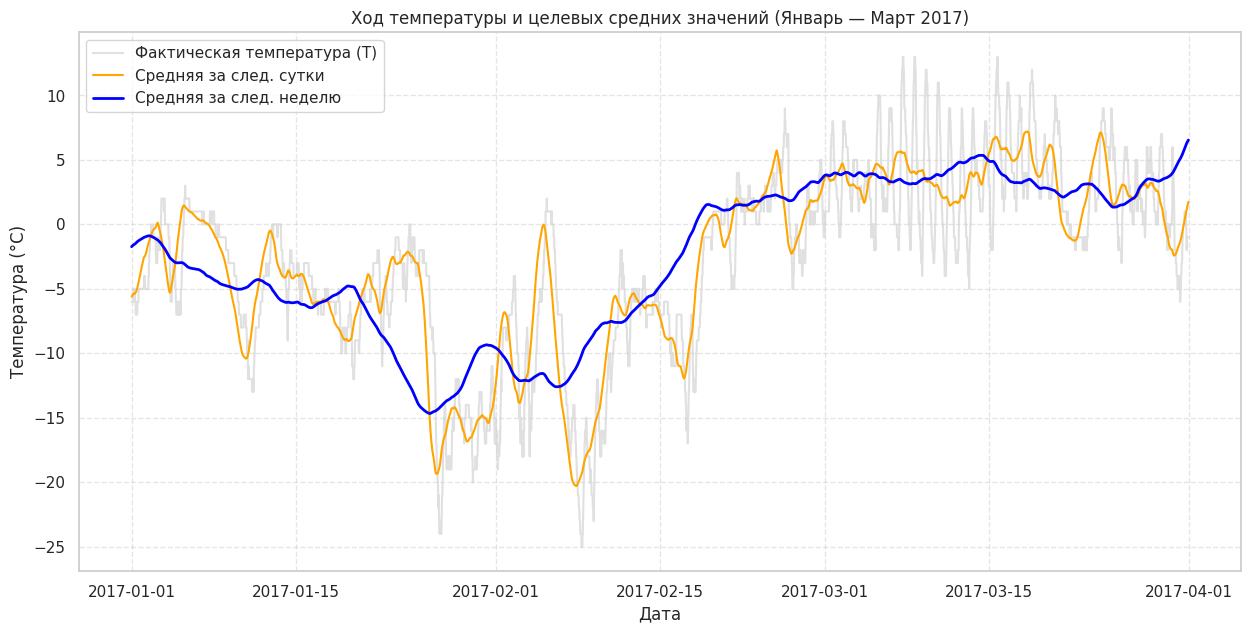

In [ ]:
data_2017_jan_mar = data.loc['2017-01':'2017-03']

plt.figure(figsize=(15, 7))
plt.plot(data_2017_jan_mar.index, data_2017_jan_mar['T'], label='Фактическая температура (T)', color='lightgray', alpha=0.7)
plt.plot(data_2017_jan_mar.index, data_2017_jan_mar['target_temp_next_day'], label='Средняя за след. сутки', color='orange', linewidth=1.5)
plt.plot(data_2017_jan_mar.index, data_2017_jan_mar['target_temp_next_week'], label='Средняя за след. неделю', color='blue', linewidth=2.0)

plt.title('Ход температуры и целевых средних значений (Январь — Март 2017)')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

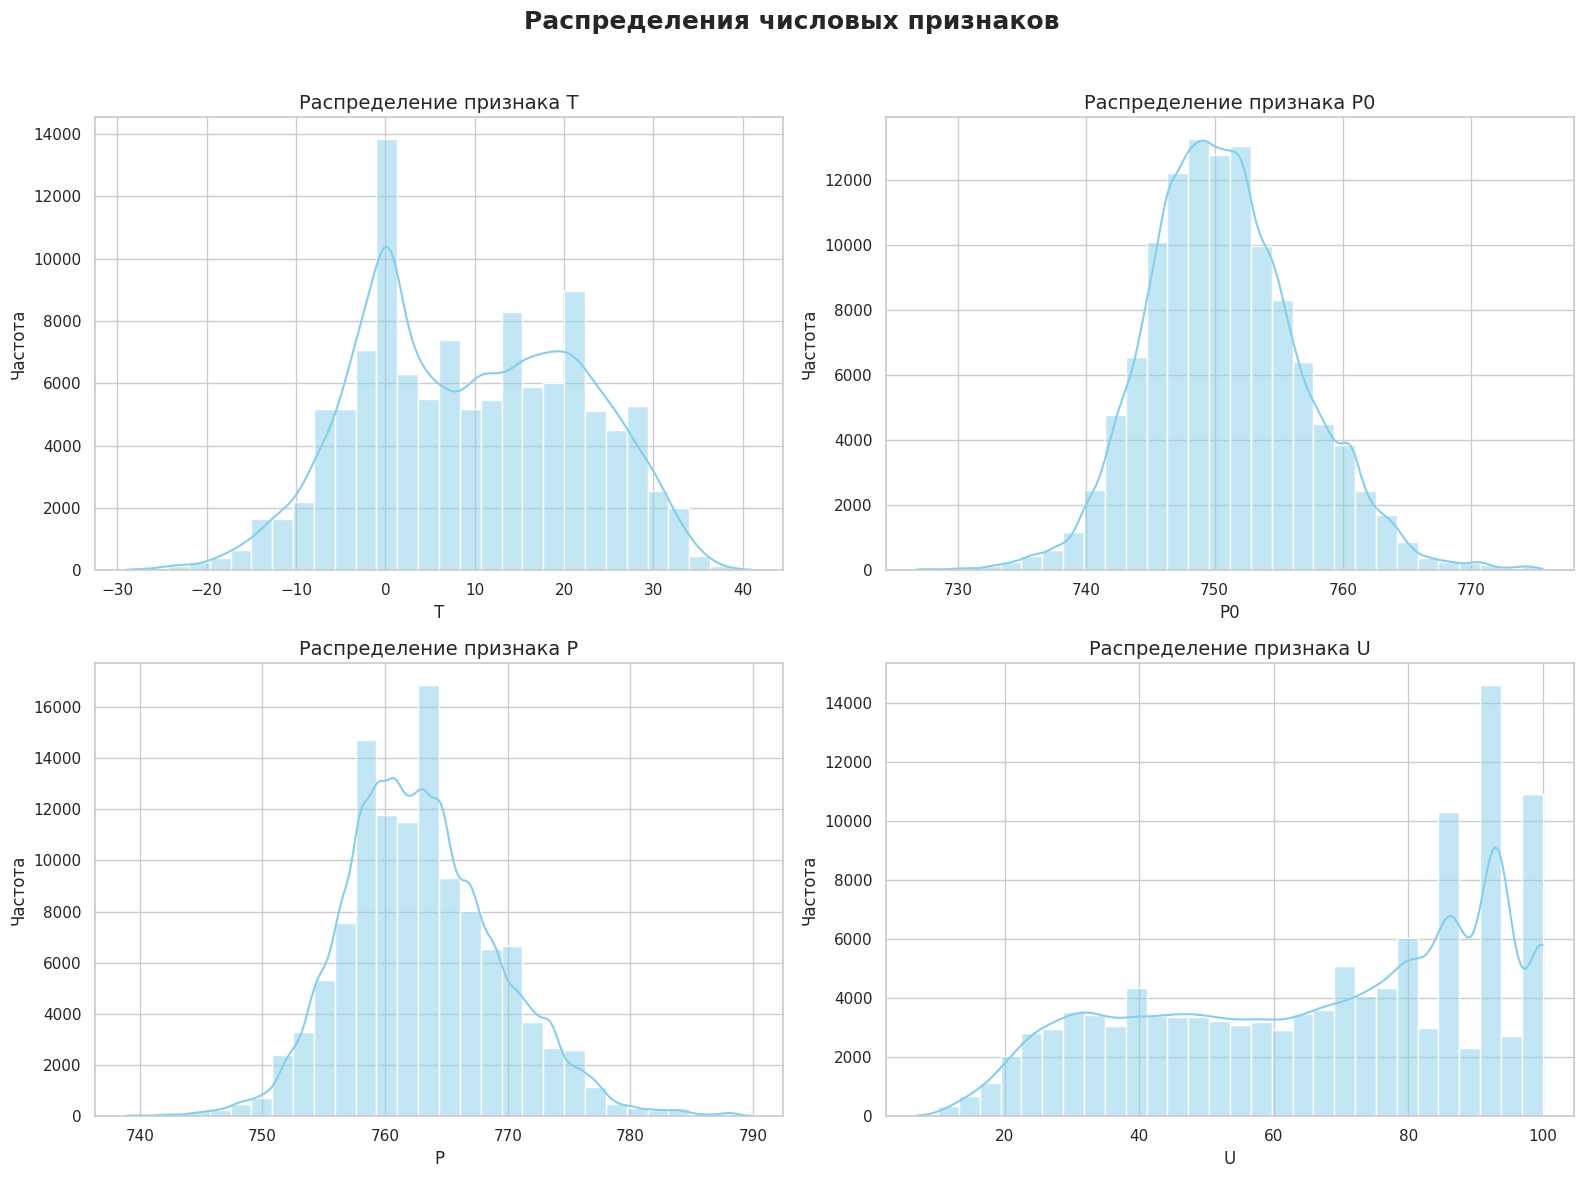

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

num_cols = ['T', 'P0', 'P', 'U']
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Распределения числовых признаков', fontsize=18, fontweight='bold')

for i, col in enumerate(num_cols):
    ax = axes[i // 2, i % 2]
    sns.histplot(data=data, x=col, kde=True, ax=ax, color='skyblue', bins=30)
    ax.set_title(f'Распределение признака {col}', fontsize=14)
    ax.set_xlabel(col, fontsize=12)
    ax.set_ylabel('Частота', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

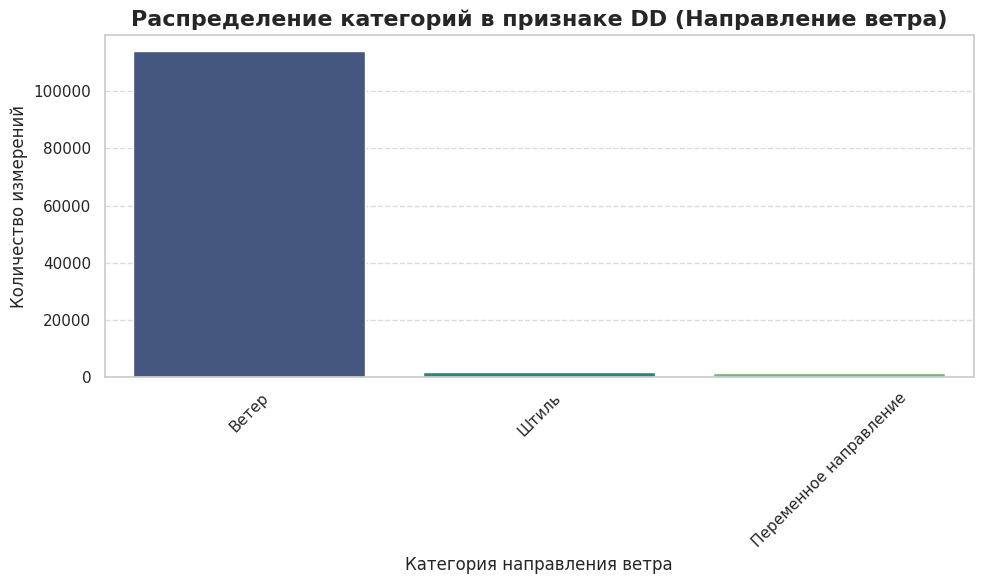

Частоты значений в колонке DD:
DD
Ветер                     114033
Штиль                       1753
Переменное направление      1469
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(10, 6))
dd_counts = data['DD'].value_counts()
sns.barplot(x=dd_counts.index, y=dd_counts.values, palette='viridis', hue=dd_counts.index, legend=False)

plt.title('Распределение категорий в признаке DD (Направление ветра)', fontsize=16, fontweight='bold')
plt.xlabel('Категория направления ветра', fontsize=12)
plt.ylabel('Количество измерений', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Частоты значений в колонке DD:")
print(dd_counts)

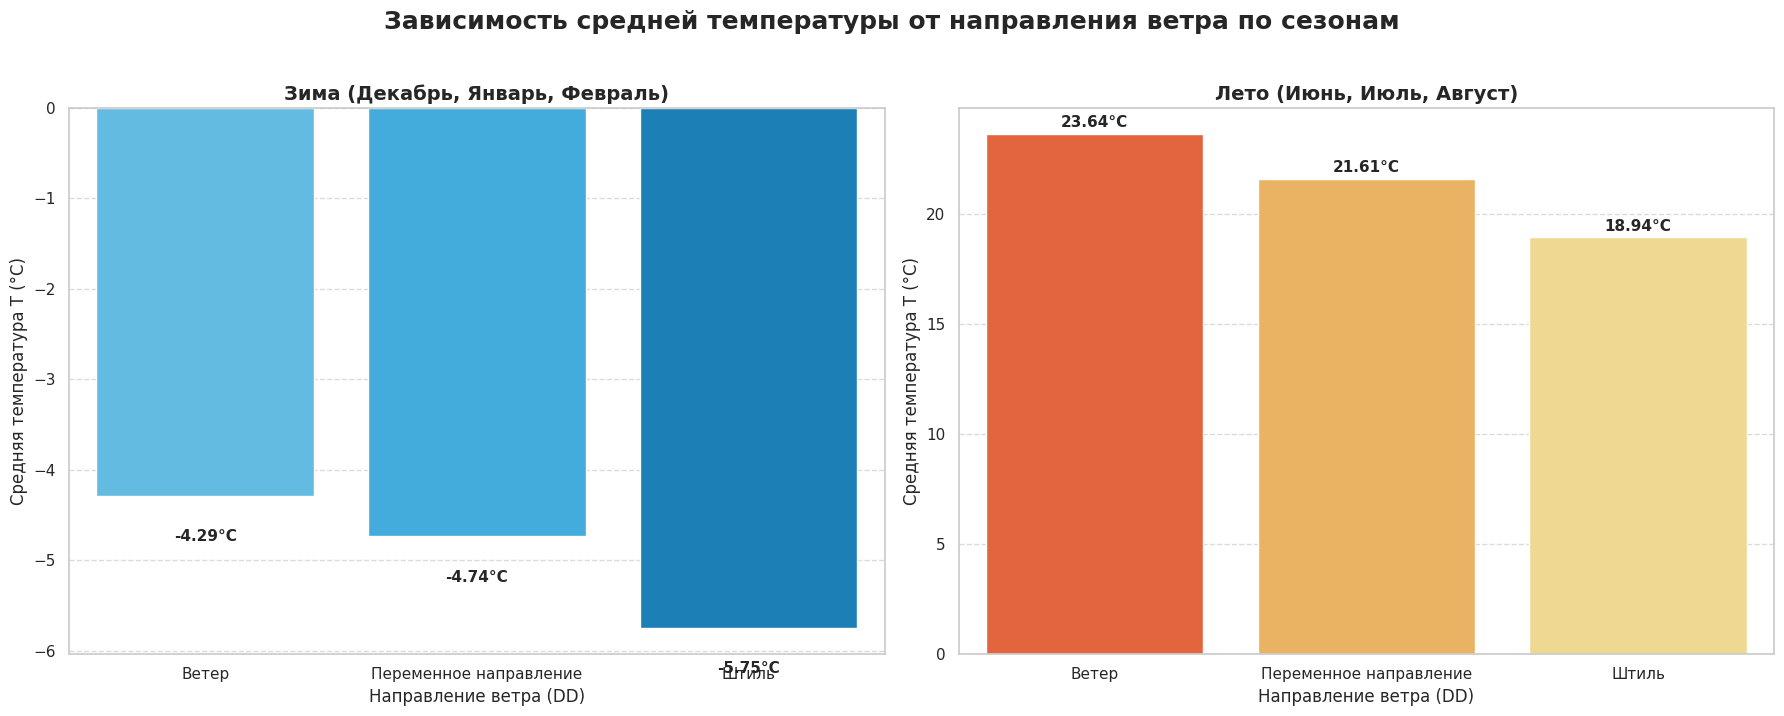

--- Зима ---
DD
Ветер                    -4.286077
Переменное направление   -4.737828
Штиль                    -5.752315
Name: T, dtype: float64

--- Лето ---
DD
Ветер                     23.640915
Переменное направление    21.605206
Штиль                     18.937669
Name: T, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

winter_data = data[data.index.month.isin([12, 1, 2])]
summer_data = data[data.index.month.isin([6, 7, 8])]

mean_temp_winter = winter_data.groupby('DD')['T'].mean().sort_values(ascending=False)
mean_temp_summer = summer_data.groupby('DD')['T'].mean().sort_values(ascending=False)

summer_colors = ['#ff5722', '#ffb74d', '#ffe082']
winter_colors = ['#4fc3f7', '#29b6f6', '#0288d1']

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=False)

sns.barplot(
    x=mean_temp_winter.index,
    y=mean_temp_winter.values,
    palette=winter_colors,
    hue=mean_temp_winter.index,
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Зима (Декабрь, Январь, Февраль)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Направление ветра (DD)', fontsize=12)
axes[0].set_ylabel('Средняя температура T (°C)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for i, val in enumerate(mean_temp_winter.values):
    axes[0].text(i, val + (0.1 if val >= 0 else -0.5), f"{val:.2f}°C", ha='center', fontweight='bold', fontsize=11)

sns.barplot(
    x=mean_temp_summer.index,
    y=mean_temp_summer.values,
    palette=summer_colors,
    hue=mean_temp_summer.index,
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Лето (Июнь, Июль, Август)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Направление ветра (DD)', fontsize=12)
axes[1].set_ylabel('Средняя температура T (°C)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for i, val in enumerate(mean_temp_summer.values):
    axes[1].text(i, val + 0.3, f"{val:.2f}°C", ha='center', fontweight='bold', fontsize=11)

fig.suptitle('Зависимость средней температуры от направления ветра по сезонам', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("--- Зима ---")
print(mean_temp_winter)
print("\n--- Лето ---")
print(mean_temp_summer)

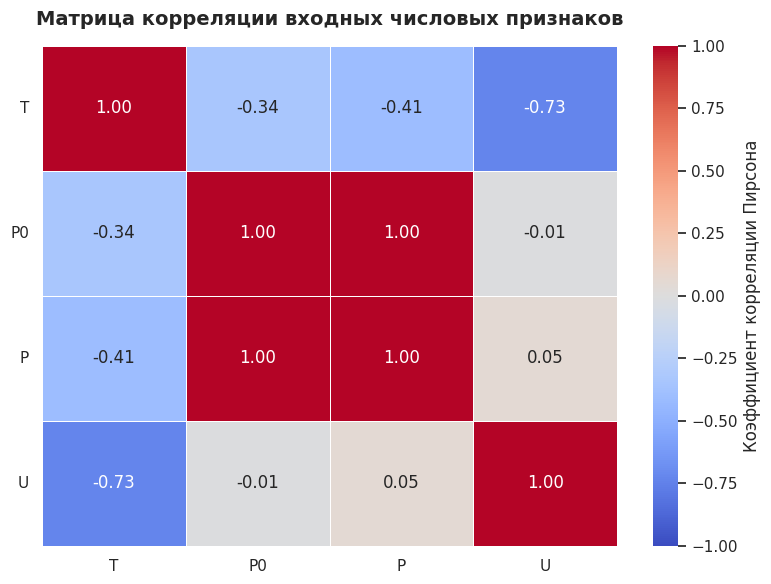

In [ ]:
feature_cols = ['T', 'P0', 'P', 'U']
features_corr_matrix = data[feature_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    features_corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Коэффициент корреляции Пирсона'}
)

plt.title('Матрица корреляции входных числовых признаков', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
data = data.drop(columns=['P0'])

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data_encoded = pd.get_dummies(data, columns=['DD'], dtype=float)

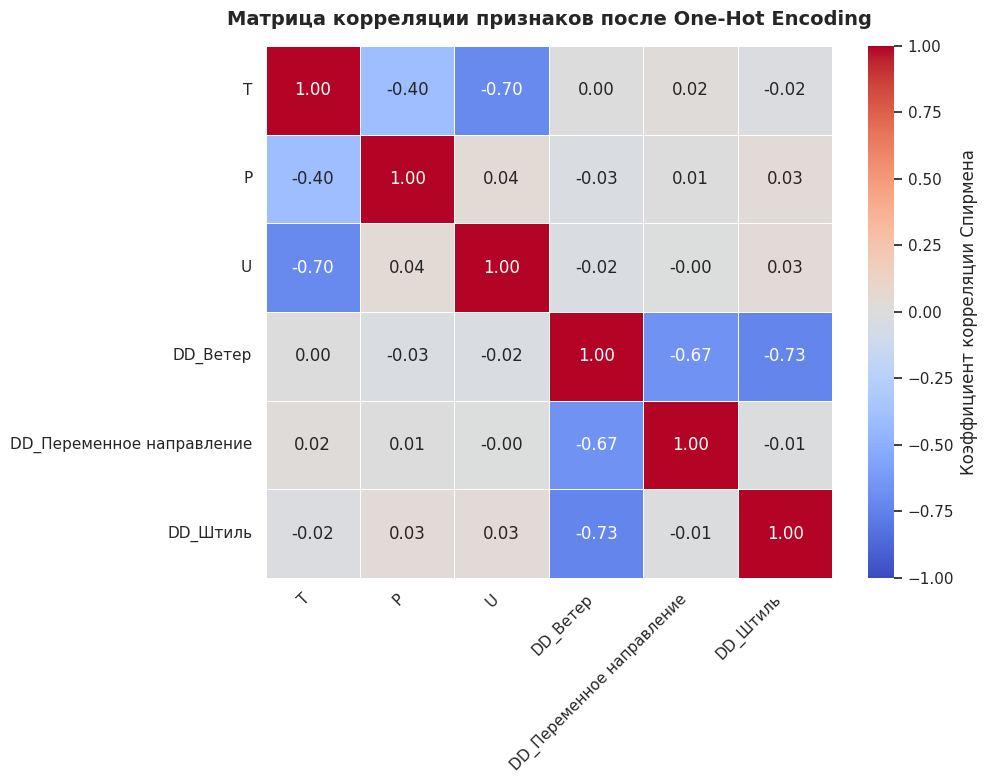

In [ ]:
columns_to_corr = ['T', 'P', 'U'] + [col for col in data_encoded.columns if col.startswith('DD_')]

encoded_corr_matrix = data_encoded[columns_to_corr].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(
    encoded_corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Коэффициент корреляции Спирмена'}
)

plt.title('Матрица корреляции признаков после One-Hot Encoding', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

data = data_encoded

In [ ]:
data

,T,P,U,target_temp_next_day,target_temp_next_week,DD_Ветер,DD_Переменное направление,DD_Штиль
LocalTime,,,,,,,,
2012-10-15 00:00:00,5.0,768.9,76.0,10.791667,12.095238,1.0,0.0,0.0
2012-10-15 01:00:00,6.0,768.9,81.0,11.083333,12.101190,1.0,0.0,0.0
2012-10-15 02:00:00,5.0,769.6,81.0,11.416667,12.107143,1.0,0.0,0.0
2012-10-15 03:00:00,6.0,769.6,76.0,11.666667,12.101190,1.0,0.0,0.0
2012-10-15 04:00:00,7.0,768.9,71.0,11.875000,12.089286,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2020-10-15 19:30:00,13.0,764.3,82.0,12.000000,12.000000,1.0,0.0,0.0
2020-10-15 20:00:00,13.0,764.3,88.0,11.750000,11.750000,1.0,0.0,0.0
2020-10-15 20:30:00,13.0,764.3,82.0,11.333333,11.333333,1.0,0.0,0.0


In [ ]:
data.to_csv('weather.csv', date_format='%d.%m.%Y %H:%M')